# Test narration using bubble contours
Standalone page experiment using local Magi + Paddle OCR, YOLO bubbles, and the tested contour checks. No narration classifier and no full-pipeline changes.

White region with meaningful visible curved or sharp edges → SPOKEN / yellow. A closed outline is NOT required. Square or rectangular box → NARRATED / grey. No qualifying surrounding region → NARRATED / grey text rectangle. A region with insufficient shape evidence is separately labelled uncertain shape / NARRATED. Uniform colored regions are recognized, but a colored rounded region is NARRATED under this experiment's white-rounded SPOKEN rule.

Overlapping candidate bubbles are grouped before labeling when at least one lacks an individual enclosing boundary. Concatenate only surviving Magi/Paddle text in Magi reading order; merged-boundary success is not required. Original member IDs remain available.

## 1. Page, cache and contour settings
Select the godfather.venv kernel. Edit split, sequence and page below. Existing OCR/bubble caches are reused by page identity; missing caches are generated locally. Bubble crops expand by **20% of original width/height on each side**, clipped to the page. Original Magi boxes and reading order stay intact.


In [ ]:
import os,sys,json,hashlib,gc,math,re,importlib.util
os.environ['HF_HUB_OFFLINE']='1'
os.environ['TRANSFORMERS_OFFLINE']='1'
import torch  # Before Paddle on this machine.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image
from IPython.display import display
from difflib import SequenceMatcher

PROJECT=Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi')
SPLIT='test'
SEQUENCE_ID='seq_14469aeb38963085'
PAGE_NUMBER=1
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
MAGI_MODEL=Path(r'C:\MODELS\magiv2')
BUBBLE_MODEL=Path(r'C:\MODELS\manga_bubbles\bubbles_detect.pt')
PADDLE_DET_PATH=Path.home()/'.paddlex/official_models/PP-OCRv5_server_det'
PADDLE_REC_PATH=Path.home()/'.paddlex/official_models/en_PP-OCRv5_mobile_rec'
EXPERIMENT=PROJECT/'FINETUNING-EXPERMENTS/NarrationModelwBubbles'
CACHE_ROOTS=[EXPERIMENT/'cache_selected_ocr/full_pipeline',PROJECT/'paddleOCR-Magi/cache_inference']
CACHE=PROJECT/'paddleOCR-Magi/cache_test_contour_narrator'
DETECTION=dict(imgsz=1024,confidence=.25)
OCR_AGREEMENT_DELETE_BELOW=.4
COLOR_TOLERANCE=25  # RGB distance from the interior median.
MIN_SOLID_FRACTION=.85
REGION=dict(min_text_coverage=.90,min_outside_fraction=.15,min_area_ratio=1.15,
            min_white_fraction=.85,min_solid_fraction=MIN_SOLID_FRACTION,color_tolerance=COLOR_TOLERANCE,
            min_visible_points=16,min_curved_fraction=.12,min_curve_run=6,min_sharp_fraction=.12,min_sharp_run=6,
            curve_override_fraction=.25,curve_override_run=12,
            rectangle_fill=.94,box_axis_tolerance_deg=12,box_axis_fraction=.90,edge_margin=2)
SAVE_RESULTS=True

SPLIT=SPLIT.strip();SEQUENCE_ID=SEQUENCE_ID.strip();PAGE_NUMBER=int(PAGE_NUMBER)
sequence_folder=PROJECT/'TaskData'/SPLIT/'images'/SEQUENCE_ID
if not sequence_folder.is_dir():
    matches=list((PROJECT/'TaskData').glob('*/images/'+SEQUENCE_ID))
    assert len(matches)==1,f'Sequence not found: {sequence_folder}'
    sequence_folder=matches[0];SPLIT=sequence_folder.parent.parent.name
PAGE_FILES=sorted(p for p in sequence_folder.glob('*.png') if p.stem.isdigit() and int(p.stem)==PAGE_NUMBER)
assert len(PAGE_FILES)==1,f'Page {PAGE_NUMBER} not found in {sequence_folder}'
PAGE_PATH=PAGE_FILES[0]
image=Image.open(PAGE_PATH).convert('RGB')
CACHE.mkdir(parents=True,exist_ok=True)
def file_hash(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
sha256=file_hash
PAGE_HASH=file_hash(PAGE_PATH)
def digest(value):return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=True,allow_nan=False).encode()).hexdigest()
def read_payload(path):
    payload=json.loads(Path(path).read_text(encoding='utf-8'))
    assert digest(payload['data'])==payload['data_hash'],f'Invalid cache checksum: {path}'
    return payload['data']
helper_path=PROJECT/'paddleOCR-Magi/contour_grouping.py'
spec=importlib.util.spec_from_file_location('test_narrator_contours',helper_path)
contours=importlib.util.module_from_spec(spec);spec.loader.exec_module(contours)
CHECK=dict(contours.CHECK,expand=.20)
print(PAGE_PATH,'|',image.size,'| padding per side:',CHECK['expand'])


C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\test\images\seq_14469aeb38963085\02.png | (979, 1400) | padding per side: 0.2


## 2. Reuse OCR or generate it for this page
The cache discovery and local fallback below reuse the code from giberish_detection.ipynb. Only Magi/Paddle run when matching OCR is unavailable. No comparison packages are needed.


In [2]:
def cached_page(path):
    sha=file_hash(path)
    with Image.open(path) as im: size=im.size
    for root in CACHE_ROOTS:
        for manifest_path in sorted(root.rglob('manifest.json')):
            try:
                manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
                matches=[i for i,p in enumerate(manifest['inputs']['pages'])
                         if p['sha256']==sha and (p['width'],p['height'])==size]
                if len(matches)!=1:continue
                index=matches[0]
                selection_path=manifest_path.with_name('ocr_selection.json')
                if selection_path.is_file():
                    page=read_payload(selection_path)[index]
                    if all(v['text_index']==i for i,v in enumerate(page)):
                        return [dict(box=v['box'],magi_text=v['magi_text'],paddle_text=v['paddle_text'],
                            paddle_lines=v.get('paddle_lines',[]),selected_text=v.get('selected_text',''),
                            paddle_status=v.get('paddle_status','cached'),paddle_error=v.get('paddle_error')) for v in page],str(selection_path)
                raw=read_payload(manifest_path.with_name('magi_raw.json'))[index]
                paddle=read_payload(manifest_path.with_name('paddle_ocr.json'))[index]
                if len(raw['texts'])!=len(paddle):continue
                if not all(v['box']==b for v,b in zip(paddle,raw['texts'])):continue
                return [dict(box=b,magi_text=t,paddle_text=v['text'],paddle_lines=v['lines'],
                    selected_text=None,paddle_status=v['status'],paddle_error=v.get('error'))
                    for b,t,v in zip(raw['texts'],raw['ocr'],paddle)],str(manifest_path.parent)
            except (OSError,KeyError,ValueError,AssertionError,IndexError,TypeError):
                continue
    return None,None

pages={}
for path in PAGE_FILES:
    records,source=cached_page(path)
    if records is not None:pages[str(path)]=dict(records=records,source=source)
    print('CACHE' if records is not None else 'MISSING',path.name,source or '')

def model_identity(path):
    return {str(p.relative_to(path)):[p.stat().st_size,p.stat().st_mtime_ns]
            for p in sorted(Path(path).rglob('*')) if p.is_file()
            and p.suffix in {'.json','.py','.bin','.safetensors','.pdparams','.pdiparams','.yml'}}

missing_pages=[p for p in PAGE_FILES if str(p) not in pages]
identity=None
if missing_pages:
    identity=dict(magi=str(MAGI_MODEL),magi_files=model_identity(MAGI_MODEL),
        paddle_det=str(PADDLE_DET_PATH),det_files=model_identity(PADDLE_DET_PATH),
        paddle_rec=str(PADDLE_REC_PATH),rec_files=model_identity(PADDLE_REC_PATH),algorithm=1)
    for path in list(missing_pages):
        cache_path=CACHE/(digest(dict(page=file_hash(path),models=identity))+'.json')
        if cache_path.is_file():
            try:
                pages[str(path)]=dict(records=read_payload(cache_path),source=str(cache_path))
                missing_pages.remove(path)
            except (OSError,ValueError,KeyError,AssertionError):pass

if missing_pages:
    from transformers import AutoConfig,AutoModel
    assert MAGI_MODEL.is_dir(),f'Missing Magi: {MAGI_MODEL}'
    config=AutoConfig.from_pretrained(str(MAGI_MODEL),trust_remote_code=True,local_files_only=True)
    config.detection_model_config.use_pretrained_backbone=False
    config.disable_ocr=False
    config.disable_detections=False
    model=AutoModel.from_pretrained(str(MAGI_MODEL),config=config,
        trust_remote_code=True,local_files_only=True).to(DEVICE).eval()
    raw_pages=[]
    try:
        for path in missing_pages:
            with Image.open(path) as im:array=np.asarray(im.convert('L').convert('RGB'))
            with torch.inference_mode():
                raw_pages.append(model.do_chapter_wide_prediction([array],{'images':[],'names':[]},do_ocr=True)[0])
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    import paddle
    from paddleocr import PaddleOCR
    assert PADDLE_DET_PATH.is_dir() and PADDLE_REC_PATH.is_dir(),'Set local Paddle model directories.'
    engine=PaddleOCR(text_detection_model_name='PP-OCRv5_server_det',
        text_recognition_model_name='en_PP-OCRv5_mobile_rec',
        text_detection_model_dir=str(PADDLE_DET_PATH),text_recognition_model_dir=str(PADDLE_REC_PATH),
        device='gpu:0' if DEVICE=='cuda' else 'cpu',
        use_doc_orientation_classify=False,use_doc_unwarping=False,use_textline_orientation=False)
    try:
        for path,raw in zip(missing_pages,raw_pages):
            with Image.open(path) as im:im=im.convert('L').convert('RGB')
            records=[]
            for box,magi_text in zip(raw['texts'],raw['ocr']):
                a,b,c,d=box
                bounds=[max(0,math.floor(a)),max(0,math.floor(b)),min(im.width,math.ceil(c)),min(im.height,math.ceil(d))]
                lines=[];error=None
                try:
                    assert bounds[2]>bounds[0] and bounds[3]>bounds[1],'Invalid crop'
                    for prediction in engine.predict(input=np.asarray(im.crop(bounds))):
                        lines.extend(dict(text=str(t),confidence=float(s))
                            for t,s in zip(prediction['rec_texts'],prediction['rec_scores']))
                except Exception as exc:error=str(exc)
                records.append(dict(box=box,magi_text=magi_text,paddle_text=' '.join(v['text'] for v in lines),
                    paddle_lines=lines,selected_text=None,paddle_status='error' if error else 'text' if lines else 'empty',paddle_error=error))
            cache_path=CACHE/(digest(dict(page=file_hash(path),models=identity))+'.json')
            cache_path.write_text(json.dumps(dict(data=records,data_hash=digest(records)),indent=2,ensure_ascii=True),encoding='utf-8')
            pages[str(path)]=dict(records=records,source=str(cache_path))
            print('CREATED',path.name,cache_path)
    finally:
        del engine
        gc.collect()
        if DEVICE=='cuda':paddle.device.cuda.empty_cache()
print('Ready:',len(pages),'pages. Existing pipeline caches were not modified.')


CACHE 02.png C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache_selected_ocr\full_pipeline\test\seq_14469aeb38963085\sequence\ocr_selection.json
Ready: 1 pages. Existing pipeline caches were not modified.


## 3. Delete artifacts, preserving original text IDs
Delete the entire box if Magi/Paddle agreement is strictly below 0.4 or SFX occurs in any OCR source (case insensitive). Missing agreement stays. Inspect rejected records below. Only surviving texts take part in bubble matching and contour checks.


In [3]:
ocr_records=pages[str(PAGE_PATH)]['records']
texts=[];deleted=[]
for index,record in enumerate(ocr_records):
    a=''.join(re.findall('[a-z0-9]',str(record['magi_text'] or '').lower()))
    b=''.join(re.findall('[a-z0-9]',str(record['paddle_text'] or '').lower()))
    agreement=SequenceMatcher(None,a,b).ratio() if a and b else None
    reasons=[]
    if agreement is not None and agreement<OCR_AGREEMENT_DELETE_BELOW:reasons.append('OCR agreement < 0.4')
    if any('sfx' in str(record.get(k) or '').casefold() for k in ['magi_text','paddle_text','selected_text']):reasons.append('OCR contains SFX')
    item=dict(record,box_id=f'PG{PAGE_NUMBER}:T{index+1}',text_index=index,ocr_agreement=agreement,
        text=record.get('selected_text') or record['paddle_text'] or record['magi_text'],deletion_reason='; '.join(reasons))
    (deleted if reasons else texts).append(item)
display(pd.DataFrame(deleted,columns=['box_id','magi_text','paddle_text','ocr_agreement','deletion_reason']))
print('Surviving texts:',len(texts),'| deleted:',len(deleted))


,box_id,magi_text,paddle_text,ocr_agreement,deletion_reason


Surviving texts: 14 | deleted: 0


## 4. Reuse YOLO bubble detections or generate them
All detector candidates are loaded; only candidates matching surviving Magi boxes will be checked. Reuse the same detector identity/image size/confidence as the previous bubble experiment. New detections are saved only to this notebook's cache.


In [4]:
def cached_bubbles():
    root = EXPERIMENT / 'cache_selected_ocr/bubbles'
    for path in sorted(root.rglob('bubbles.json')):
        try:
            saved = json.loads(path.read_text(encoding='utf-8'))
            settings = saved['identity']['settings']
            if (saved['page']['sha256'] == PAGE_HASH
                and saved['identity']['detector_sha256'] == sha256(BUBBLE_MODEL)
                and settings['bubble_imgsz'] == DETECTION['imgsz']
                and settings['bubble_confidence'] == DETECTION['confidence']):
                return [dict(box=b['box'],confidence=b['confidence'],
                             originally_kept=b.get('kept')) for b in saved['bubbles']], str(path)
        except (KeyError,ValueError,OSError):
            continue
    return None, None

candidates,bubble_source=cached_bubbles()
if candidates is None:
    cache_path=CACHE/('bubbles_'+digest(dict(page=PAGE_HASH,weights=file_hash(BUBBLE_MODEL),settings=DETECTION))[:20]+'.json')
    if cache_path.is_file():
        candidates=read_payload(cache_path)
    else:
        from ultralytics import YOLO
        detector=YOLO(str(BUBBLE_MODEL))
        try:
            prediction=detector.predict(source=image,imgsz=DETECTION['imgsz'],conf=DETECTION['confidence'],device=DEVICE,verbose=False)[0]
            candidates=[]
            for box,score in zip(prediction.boxes.xyxy.cpu().tolist(),prediction.boxes.conf.cpu().tolist()):
                a,b,c,d=box
                bounds=[max(0,math.floor(a)),max(0,math.floor(b)),min(image.width,math.ceil(c)),min(image.height,math.ceil(d))]
                if bounds[2]>bounds[0] and bounds[3]>bounds[1]:candidates.append(dict(box=bounds,confidence=float(score)))
            candidates.sort(key=lambda v:(v['box'][1],-v['box'][0]))
            cache_path.write_text(json.dumps(dict(data=candidates,data_hash=digest(candidates)),indent=2),encoding='utf-8')
        finally:
            del detector
            gc.collect()
            if torch.cuda.is_available():torch.cuda.empty_cache()
    bubble_source=str(cache_path)
print('YOLO candidates:',len(candidates),'| source:',bubble_source)


YOLO candidates: 16 | source: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache_selected_ocr\bubbles\full_pipeline\seq_14469aeb38963085\page_02\ee3fdfa0f9230c7f\bubbles.json


## 5. Select overlapping groups and concatenate OCR
Reuse the existing boundary and faint-retry checks. Include verified neighbors, but skip overlapping groups whose members all have individual boundaries. This step selects groups only; it does not require a merged boundary or assign a narration label. Each surviving text appears in exactly one output row.


In [5]:
def union_box(boxes):
    return [min(b[0] for b in boxes),min(b[1] for b in boxes),
            max(b[2] for b in boxes),max(b[3] for b in boxes)]


# Existing strict/faint boundary checks ONLY select merge candidates; they do not label speech.
grouping_records=[dict(t,delete_ocr=False) for t in texts]
page_groups=contours.inspect_page_groups(candidates,image,grouping_records,CHECK)
lookup={t['box_id']:i for i,t in enumerate(texts)}
units=[];assigned=set()
memberships={bid:[] for bid in lookup}
for proposal in page_groups['merge_candidates']:
    for bid in proposal['text_ids']:
        if bid in memberships:memberships[bid].append(proposal['group_id'])
for proposal in page_groups['merge_candidates']:
    # First proposal wins deterministically; ambiguous membership remains visible for review.
    indices=sorted((lookup[bid] for bid in proposal['text_ids'] if bid in lookup and bid not in assigned),
                   key=lambda i:texts[i]['text_index'])
    if len(indices)<2:continue
    ids=[texts[i]['box_id'] for i in indices];assigned.update(ids)
    units.append(dict(group_id=f"PG{PAGE_NUMBER}:"+proposal['group_id'],member_indices=indices,
        candidate_ids=proposal['candidate_ids'],grouping_source='overlap_candidate',
        needs_review=any(len(memberships[bid])>1 for bid in ids)))
for i,text in enumerate(texts):
    if text['box_id'] not in assigned:
        units.append(dict(group_id=text['box_id'],member_indices=[i],candidate_ids=[],
            grouping_source='standalone',needs_review=len(memberships[text['box_id']])>1))
units.sort(key=lambda unit:texts[unit['member_indices'][0]]['text_index'])
group_table=pd.DataFrame([dict(group_id=u['group_id'],box_ids=[texts[i]['box_id'] for i in u['member_indices']],
    candidate_ids=u['candidate_ids'],text=' '.join(texts[i]['text'] for i in u['member_indices']),
    grouping_source=u['grouping_source'],needs_review=u['needs_review']) for u in units])
display(pd.DataFrame(page_groups['individual']).reindex(columns=['candidate_id','text_ids','boundary_found','detection_pass']))
display(group_table)
print(len(texts),'surviving texts ->',len(units),'rows before classification')


,candidate_id,text_ids,boundary_found,detection_pass
0,0,[PG2:T1],False,first
1,1,[PG2:T3],False,first
2,2,[PG2:T2],False,first
3,3,[PG2:T4],False,first
4,4,[PG2:T6],False,first
5,5,[PG2:T5],False,first
6,10,[PG2:T9],False,first
7,11,[PG2:T8],False,first
8,12,[PG2:T7],False,first
9,13,[PG2:T10],False,first


,group_id,box_ids,candidate_ids,text,grouping_source,needs_review
0,PG2:T1,[PG2:T1],[],Her mother took her and her brother,standalone,False
1,PG2:T2,[PG2:T2],[],and left her husband's house,standalone,False
2,PG2:T3,[PG2:T3],[],With the support of her lover.her mother start...,standalone,False
3,PG2:T4,[PG2:T4],[],"...However,it seems that she wasn't very skill...",standalone,False
4,PG2:T5,[PG2:T5],[],Saiko-chan and her older brother,standalone,False
5,PG2:T6,[PG2:T6],[],joined the cheap-in-tuition CCG Academy Junior...,standalone,False
6,PG2:M1,"[PG2:T7, PG2:T8, PG2:T9]","[10, 11, 12]","ORIGINALLY, SINCE SHE HAD NO INTENTION OF BECO...",overlap_candidate,False
7,PG2:M2,"[PG2:T10, PG2:T11]","[13, 15]",YEAH. SHE'D BRING HER GAMES TO LECTURE TOO.,overlap_candidate,False
8,PG2:T12,[PG2:T12],[],YONE- BAYA- SHI.,standalone,False
9,PG2:T13,[PG2:T13],[],SHE PISSED THE TEACHER OFF SO MUCH..,standalone,False


14 surviving texts -> 11 rows before classification


## 5. Find the background mass and inspect visible shape
Match surviving text to a YOLO crop (80% text coverage), pad by 20% per side, and find connected white or dominant-color regions associated with it. Fill letter holes for coverage; exclude OCR rectangles when measuring background consistency. A substantial region must cover at least 90% of the text rectangle, extend beyond it, and be mostly white or uniform in color. Touching the crop edge is allowed. Crop edges and their curvature neighborhoods supply no shape evidence. Meaningful visible curved OR sharp runs make a white region SPOKEN. Square/rectangular and stepped box-like regions remain NARRATED; visible straight sides aligned in two perpendicular directions take priority over sharp-edge evidence. Substantial visible curves (at least 25% curved samples and a run of 12) override a box-like approximation, since rounded bubbles can also have long straight sides. Crop-border segments are excluded from this check. Overlap groups are concatenated first. Shared-region measurements use the union of original member text rectangles, not the empty space between them. Disconnected regions are checked separately in the same combined crop; conflicting labels or missing member regions fall back to NARRATED with needs_review=True. Group metrics describe the shared region or first member region, with individual decisions in region_predictions. REGION thresholds above are configurable.


In [6]:
def longest_run(values):
    # Boundary samples are circular; a curve can cross the first/last sample.
    longest=current=0
    for value in np.r_[values,values]:
        current=current+1 if value else 0
        longest=max(longest,current)
    return min(longest,len(values))


def box_like_profile(contour,gray):
    # Simplify small jagged edges, then look for two perpendicular families of straight sides.
    perimeter=cv2.arcLength(contour,True)
    polygon=cv2.approxPolyDP(contour,max(1.,.008*perimeter),True)[:,0].astype(float)
    starts=polygon;ends=np.roll(polygon,-1,axis=0)
    vectors=ends-starts;lengths=np.linalg.norm(vectors,axis=1)
    height,width=gray.shape;edge=REGION['edge_margin']
    nearby=cv2.dilate(cv2.Canny(gray,25,80),np.ones((5,5),np.uint8))>0
    valid=lengths>=max(4.,.02*perimeter)
    # Only use image-supported segments inside the crop; crop borders are never box evidence.
    for i,(a,b) in enumerate(zip(starts,ends)):
        samples=np.rint(a[None,:]+np.linspace(0,1,9)[:,None]*(b-a)).astype(int)
        inside=((samples[:,0]>edge)&(samples[:,0]<width-1-edge)&
                (samples[:,1]>edge)&(samples[:,1]<height-1-edge))
        valid[i] &= bool(inside.all() and nearby[samples[:,1],samples[:,0]].mean()>=.75)
    if np.count_nonzero(valid)<3:return False,0.
    angles=np.degrees(np.arctan2(vectors[valid,1],vectors[valid,0]))%180
    weights=lengths[valid];best=0.;box_like=False
    for axis in angles:
        difference=np.abs((angles-axis+90)%180-90)
        parallel=difference<=REGION['box_axis_tolerance_deg']
        perpendicular=np.abs(difference-90)<=REGION['box_axis_tolerance_deg']
        fraction=float(weights[parallel|perpendicular].sum()/weights.sum())
        best=max(best,fraction)
        # Both directions must contribute; one long straight edge is insufficient.
        if (fraction>=REGION['box_axis_fraction'] and weights[parallel].sum()/weights.sum()>=.15
            and weights[perpendicular].sum()/weights.sum()>=.15):box_like=True
    return box_like,best


def find_background_regions(candidate,page_image,text_boxes,target_index):
    target_indices=[target_index] if isinstance(target_index,int) else list(target_index)
    a,b,c,d=candidate['box'];dx=(c-a)*CHECK['expand'];dy=(d-b)*CHECK['expand']
    bounds=[max(0,math.floor(a-dx)),max(0,math.floor(b-dy)),
            min(page_image.width,math.ceil(c+dx)),min(page_image.height,math.ceil(d+dy))]
    crop=np.asarray(page_image.crop(bounds));gray=cv2.cvtColor(crop,cv2.COLOR_RGB2GRAY)
    height,width=gray.shape
    target=np.zeros_like(gray,np.uint8);excluded=np.zeros_like(gray,np.uint8);member_masks=[]
    for i,box in enumerate(text_boxes):
        a,b,c,d=box
        x1,y1=max(0,math.floor(a-bounds[0])),max(0,math.floor(b-bounds[1]))
        x2,y2=min(width,math.ceil(c-bounds[0])),min(height,math.ceil(d-bounds[1]))
        if x2<=x1 or y2<=y1:continue
        excluded[y1:y2,x1:x2]=255
        if i in target_indices:
            target[y1:y2,x1:x2]=255
            member=np.zeros_like(gray,np.uint8);member[y1:y2,x1:x2]=255;member_masks.append(member)
    target_area=max(1,np.count_nonzero(target))
    samples=crop[target>0]
    if not len(samples):return dict(crop=crop,bounds=bounds,regions=[],best=None)
    # Find candidate white and dominant-color backgrounds; no enclosing ink outline is needed.
    binaries=[np.uint8(gray>=CHECK['white_threshold'])*255]
    quantized=samples.astype(np.int32)//32
    colors,counts=np.unique(quantized,axis=0,return_counts=True)
    for index in np.argsort(counts)[-3:]:
        color=np.median(samples[(quantized==colors[index]).all(axis=1)],axis=0)
        similar=np.linalg.norm(crop.astype(float)-color,axis=2)<=REGION['color_tolerance']
        binaries.append(np.uint8(similar)*255)
    # Visible color/ink transitions support shape; image borders never do.
    edges=cv2.Canny(gray,25,80)
    nearby=cv2.dilate(edges,np.ones((5,5),np.uint8))>0
    records=[]
    for binary in binaries:
        repaired=cv2.morphologyEx(binary,cv2.MORPH_CLOSE,np.ones((3,3),np.uint8))
        count,components,stats,_=cv2.connectedComponentsWithStats(repaired)
        ids=np.unique(components[(target>0)&(repaired>0)])
        for component_id in ids:
            if component_id==0:continue
            component=np.uint8(components==component_id)*255
            found,_=cv2.findContours(component,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
            if not found:continue
            contour=max(found,key=cv2.contourArea)
            mask=np.zeros_like(gray,np.uint8)
            cv2.drawContours(mask,[contour],-1,255,cv2.FILLED)  # Fill letter-sized holes for coverage only.
            coverage=np.count_nonzero((mask>0)&(target>0))/target_area
            # Every member must be covered; a large text must not hide a missed small one.
            if any(np.count_nonzero((mask>0)&(member>0))/max(1,np.count_nonzero(member))<REGION['min_text_coverage'] for member in member_masks):continue
            area=np.count_nonzero(mask)
            outside_fraction=np.count_nonzero((mask>0)&(target==0))/max(1,area)
            if (coverage<REGION['min_text_coverage'] or area<target_area*REGION['min_area_ratio']
                or outside_fraction<REGION['min_outside_fraction']):continue
            usable=(cv2.erode(mask,np.ones((3,3),np.uint8))>0)&(excluded==0)
            pixels=crop[usable].astype(float)
            if len(pixels)<20:continue
            white_fraction=float((gray[usable]>=CHECK['white_threshold']).mean())
            median=np.median(pixels,axis=0)
            solid_fraction=float((np.linalg.norm(pixels-median,axis=1)<=REGION['color_tolerance']).mean())
            white=white_fraction>=REGION['min_white_fraction']
            if not white and solid_fraction<REGION['min_solid_fraction']:continue
            profile=contours.boundary_profile(contour,CHECK)
            points=np.rint(profile['boundary_points']).astype(int)
            edge=REGION['edge_margin']
            on_edge=((points[:,0]<=edge)|(points[:,1]<=edge)|
                     (points[:,0]>=width-1-edge)|(points[:,1]>=height-1-edge))
            # Chord-based curvature near crop corners would be artificial; exclude that neighborhood too.
            near_edge=np.maximum.reduce([np.roll(on_edge,shift) for shift in range(-CHECK['curve_window'],CHECK['curve_window']+1)])
            visible=~near_edge & nearby[points[:,1],points[:,0]]
            labels=profile['boundary_labels']
            curved=visible & (labels=='curved')
            flat=visible & (labels=='flat')
            sharp=visible & (labels=='sharp')
            visible_count=np.count_nonzero(visible)
            curve_fraction=np.count_nonzero(curved)/max(1,visible_count)
            flat_fraction=np.count_nonzero(flat)/max(1,visible_count)
            sharp_fraction=np.count_nonzero(sharp)/max(1,visible_count)
            sharp_run=longest_run(sharp)
            rect=cv2.minAreaRect(contour);fill=cv2.contourArea(contour)/max(1,rect[1][0]*rect[1][1])
            curve_run=longest_run(curved)
            enough=visible_count>=REGION['min_visible_points']
            rounded=enough and curve_fraction>=REGION['min_curved_fraction'] and curve_run>=REGION['min_curve_run']
            # Rectangular boxes keep their caption rule; ordinary rectangle corners are not speech evidence.
            box_like,box_axis_fraction=box_like_profile(contour,gray)
            rectangular=enough and (box_like or fill>=REGION['rectangle_fill'] or (not rounded and flat_fraction>=.70))
            sharp_sides=enough and sharp_fraction>=REGION['min_sharp_fraction'] and sharp_run>=REGION['min_sharp_run']
            expressive=rounded or sharp_sides
            # A long curved side beats a box-like approximation; ordinary small corners do not.
            strong_curves=rounded and curve_fraction>=REGION['curve_override_fraction'] and curve_run>=REGION['curve_override_run']
            if white and strong_curves:
                role,reason='SPOKEN','white region with substantial curved sides; overrides box-like approximation'
            elif rectangular:
                role='NARRATED'
                reason='box-like region with straight perpendicular sides' if box_like else 'white/solid region with mainly straight rectangular sides'
            elif white and expressive:
                role='SPOKEN'
                reason='white region with meaningful visible curved sides' if rounded else 'white region with meaningful visible sharp edges'
            elif expressive:role,reason='NARRATED','curved/sharp solid-color region; not white'
            else:role,reason='NARRATED','region exists; insufficient visible shape evidence'
            records.append(dict(mask=mask,usable=usable,contour=contour,points=points,visible=visible,
                curved=curved,flat=flat,sharp=sharp,on_edge=on_edge,coverage=float(coverage),area=int(area),
                white_fraction=white_fraction,solid_fraction=solid_fraction,outside_fraction=float(outside_fraction),
                curved_fraction=float(curve_fraction),flat_fraction=float(flat_fraction),sharp_fraction=float(sharp_fraction),sharp_run=int(sharp_run),box_axis_fraction=float(box_axis_fraction),box_like=bool(box_like),strong_curves=bool(strong_curves),
                visible_points=int(visible_count),curve_run=int(curve_run),rectangularity=float(fill),
                text_role=role,reason=reason,shape_decided=bool(expressive or rectangular)))
    # Prefer a shape-supported region, then coverage and the tighter background mass.
    records.sort(key=lambda r:(not r['shape_decided'],-r['coverage'],r['area']))
    return dict(crop=crop,bounds=bounds,regions=records,best=records[0] if records else None)


def best_option(options):
    options.sort(key=lambda o:(not o['region']['shape_decided'],-o['region']['coverage'],o['region']['area'],str(o['candidate_id'])))
    return options[0] if options else None


results=[];debug=[]
text_boxes=[t['box'] for t in texts]
for unit in units:
    indices=unit['member_indices'];members=[texts[i] for i in indices]
    box=union_box([m['box'] for m in members])
    attempts=[];options=[];selected=[]
    if unit['grouping_source']=='overlap_candidate':
        # Test the combined YOLO crop, not a rectangle drawn around the text.
        candidate=dict(box=union_box([candidates[i]['box'] for i in unit['candidate_ids']]))
        checked=find_background_regions(candidate,image,text_boxes,indices)
        attempts.append(dict(candidate_id=unit['candidate_ids'],result=checked))
        if checked['best'] is not None:
            selected=[dict(candidate_id=unit['candidate_ids'],result=checked,region=checked['best'])]
        else:
            # Disconnected masses: inspect each member in that same combined crop.
            for index in indices:
                checked=find_background_regions(candidate,image,text_boxes,index)
                attempts.append(dict(candidate_id=unit['candidate_ids'],result=checked,member_id=texts[index]['box_id']))
                if checked['best'] is not None:
                    selected.append(dict(candidate_id=unit['candidate_ids'],result=checked,region=checked['best']))
    else:
        index=indices[0];area=max(1,(box[2]-box[0])*(box[3]-box[1]))
        for candidate_id,candidate in enumerate(candidates):
            if contours.overlap(box,candidate['box'])/area<.8:continue
            checked=find_background_regions(candidate,image,text_boxes,index)
            attempts.append(dict(candidate_id=candidate_id,result=checked))
            if checked['best'] is not None:
                options.append(dict(candidate_id=candidate_id,result=checked,region=checked['best']))
        chosen=best_option(options)
        if chosen:selected=[chosen]
    chosen=selected[0] if selected else None
    row=dict(box_id=unit['group_id'],box_ids=[m['box_id'] for m in members],
        member_text_boxes=[m['box'] for m in members],text_index=members[0]['text_index'],
        text=' '.join(m['text'].strip() for m in members if m['text'].strip()),
        magi_text=' '.join(str(m['magi_text'] or '').strip() for m in members),
        paddle_text=' '.join(str(m['paddle_text'] or '').strip() for m in members),
        text_box=box,text_role='NARRATED',reason='no substantial white/solid-color region around text',candidate_id=None,
        candidate_ids=unit['candidate_ids'],grouping_source=unit['grouping_source'],needs_review=unit['needs_review'],
        contour_points=[],visible_segments=[],crop_bounds=None,ocr_agreement=members[0]['ocr_agreement'] if len(members)==1 else None,
        member_ocr_agreement=[m['ocr_agreement'] for m in members],detection_pass='group_background_region',region_predictions=[])
    if chosen:
        region=chosen['region']
        row.update({k:region[k] for k in ['text_role','reason','coverage','white_fraction','solid_fraction','outside_fraction',
            'curved_fraction','flat_fraction','sharp_fraction','sharp_run','box_axis_fraction','box_like','strong_curves',
            'visible_points','curve_run','rectangularity']})
        row.update(candidate_id=chosen['candidate_id'],crop_bounds=chosen['result']['bounds'])
        for option in selected:
            region=option['region'];offset=np.array(option['result']['bounds'][:2]);points=region['points']+offset
            row['contour_points'].extend((region['contour'][:,0]+offset).tolist())
            row['visible_segments'].extend([[points[i].tolist(),points[(i+1)%len(points)].tolist()] for i in range(len(points))
                if region['visible'][i] and region['visible'][(i+1)%len(points)]])
            row['region_predictions'].append({k:region[k] for k in ['text_role','reason','coverage','curved_fraction','sharp_fraction','box_like']})
        roles={r['text_role'] for r in row['region_predictions']}
        split_attempts=[a for a in attempts if 'member_id' in a]
        missing=any(a['result']['best'] is None for a in split_attempts)
        if len(roles)>1 or missing:
            row.update(text_role='NARRATED',needs_review=True,
                reason='group has conflicting region labels' if len(roles)>1 else 'group has members without a qualifying region')
        elif len(selected)>1:row['reason']='separate regions agree: '+row['text_role']
        row['metrics_scope']='shared region' if not split_attempts else 'first member region; see region_predictions'
    elif not attempts:row['reason']='no YOLO bubble matched this surviving Magi text'
    results.append(row);debug.append(dict(attempts=attempts,chosen=chosen))
result_table=pd.DataFrame(results)
emitted=[bid for row in results for bid in row['box_ids']]
assert len(emitted)==len(set(emitted)) and set(emitted)=={t['box_id'] for t in texts},'Missing/duplicated text'
display(result_table.reindex(columns=['box_id','box_ids','text','text_role','reason','needs_review','candidate_ids']))


,box_id,box_ids,text,text_role,reason,needs_review,candidate_ids
0,PG2:T1,[PG2:T1],Her mother took her and her brother,NARRATED,no substantial white/solid-color region around...,False,[]
1,PG2:T2,[PG2:T2],and left her husband's house,NARRATED,no substantial white/solid-color region around...,False,[]
2,PG2:T3,[PG2:T3],With the support of her lover.her mother start...,NARRATED,no substantial white/solid-color region around...,False,[]
3,PG2:T4,[PG2:T4],"...However,it seems that she wasn't very skill...",SPOKEN,white region with meaningful visible sharp edges,False,[]
4,PG2:T5,[PG2:T5],Saiko-chan and her older brother,NARRATED,no substantial white/solid-color region around...,False,[]
5,PG2:T6,[PG2:T6],joined the cheap-in-tuition CCG Academy Junior...,NARRATED,no substantial white/solid-color region around...,False,[]
6,PG2:M1,"[PG2:T7, PG2:T8, PG2:T9]","ORIGINALLY, SINCE SHE HAD NO INTENTION OF BECO...",SPOKEN,white region with meaningful visible sharp edges,False,"[10, 11, 12]"
7,PG2:M2,"[PG2:T10, PG2:T11]",YEAH. SHE'D BRING HER GAMES TO LECTURE TOO.,SPOKEN,white region with meaningful visible curved sides,False,"[13, 15]"
8,PG2:T12,[PG2:T12],YONE- BAYA- SHI.,NARRATED,no YOLO bubble matched this surviving Magi text,False,[]
9,PG2:T13,[PG2:T13],SHE PISSED THE TEACHER OFF SO MUCH..,SPOKEN,white region with substantial curved sides; ov...,False,[]


## 6. Annotated page: yellow SPOKEN, grey NARRATED
Draw only the visible region boundary sections around the bubble. If no qualifying contour exists, draw the original text rectangle in grey. Optional dashed rectangles show the actual padded YOLO crops used for measurement. No deleted OCR is classified; enable the separate red overlay to inspect artifacts.


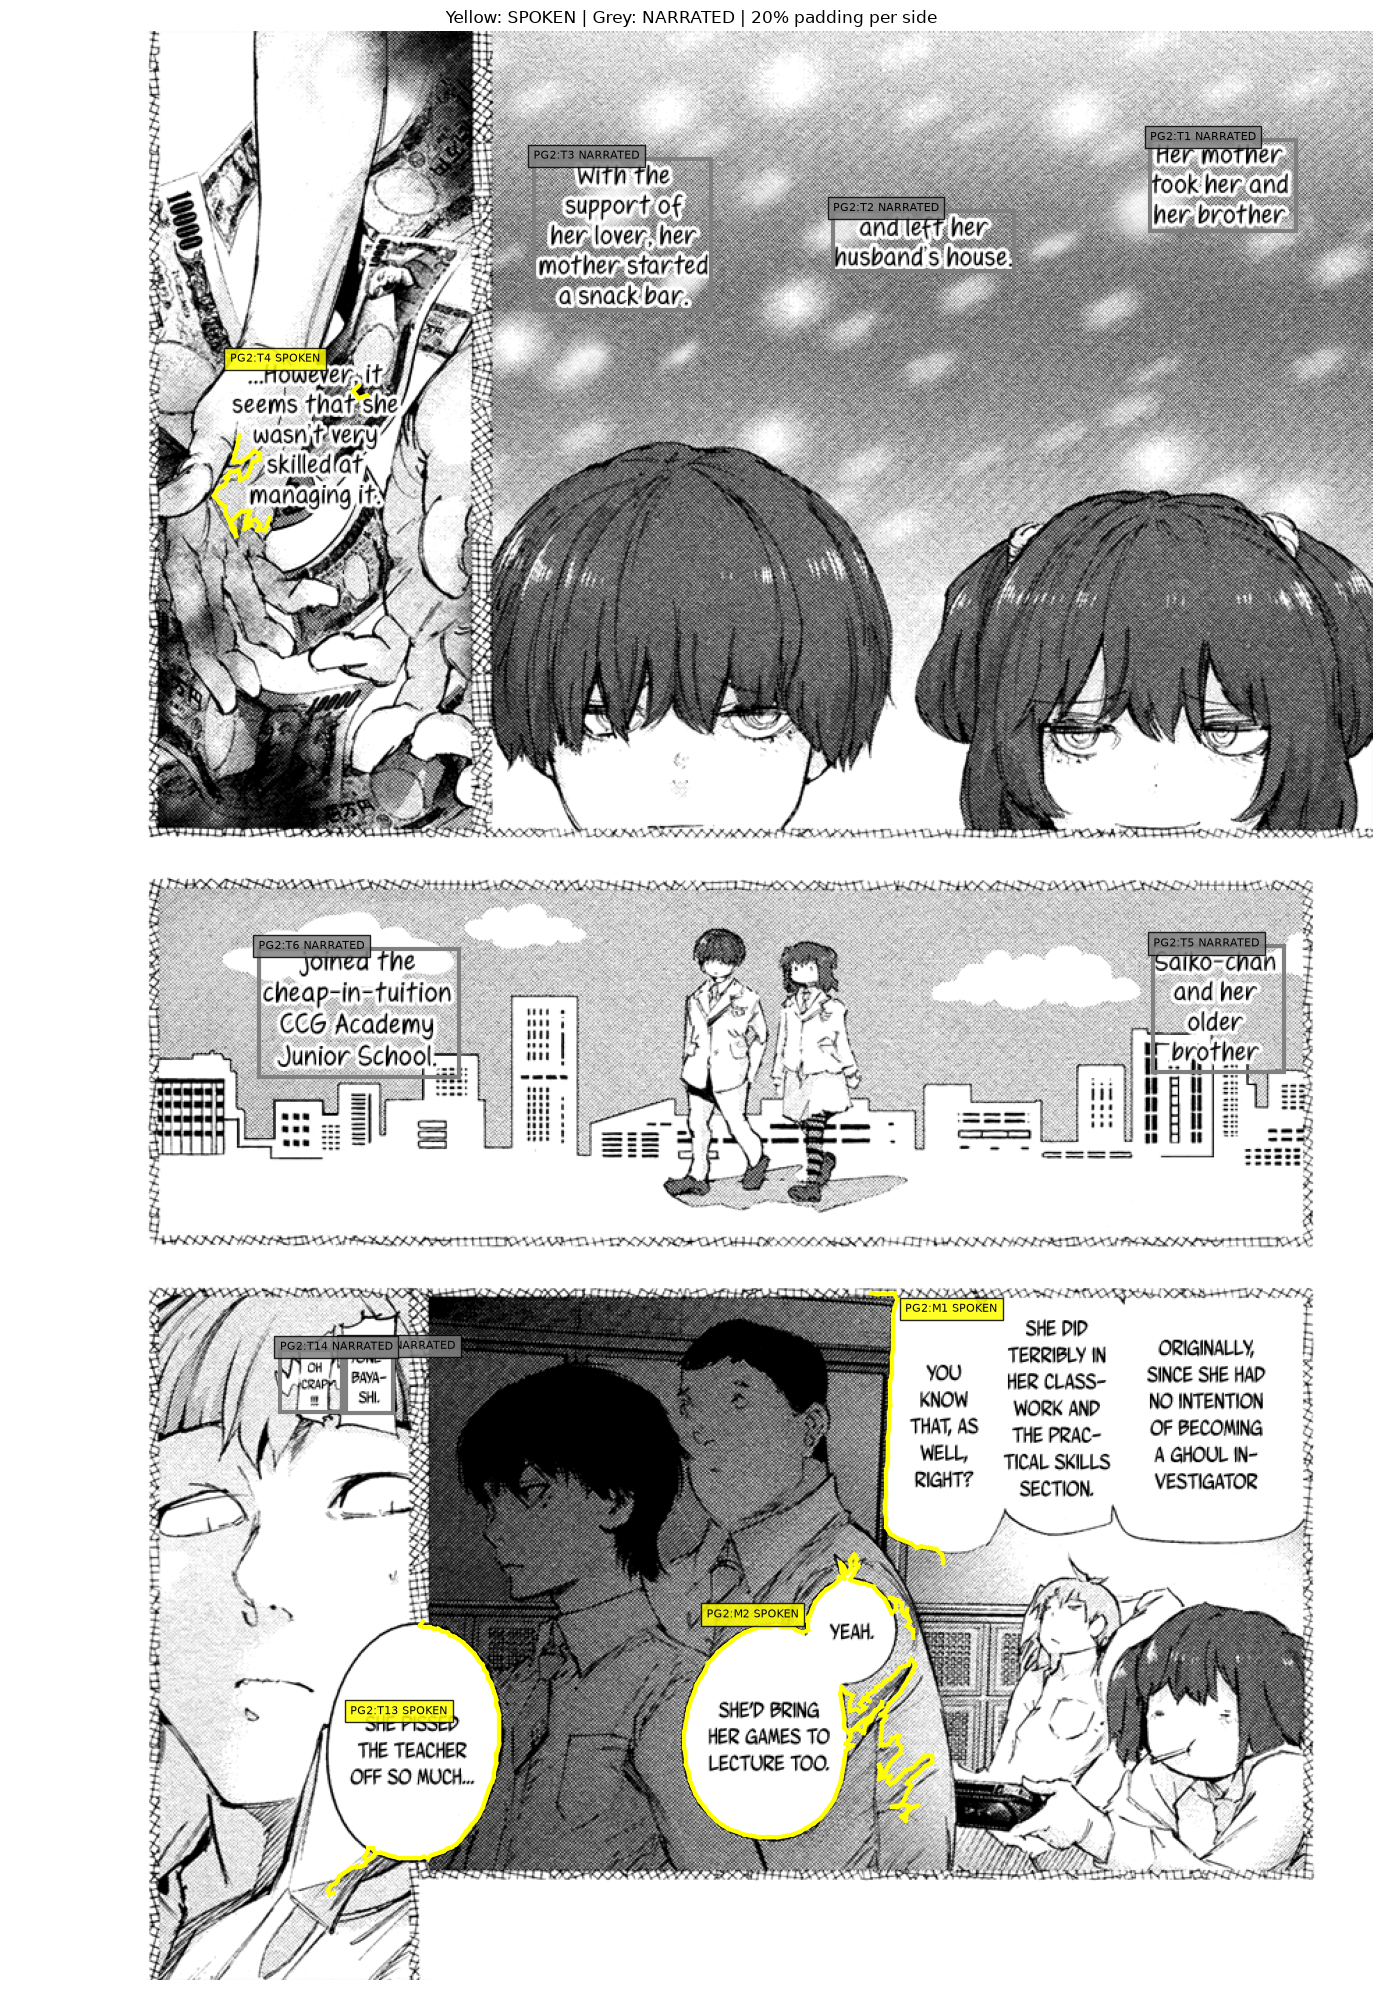

In [7]:
def show_page(show_padding=False,show_deleted=False):
    fig,ax=plt.subplots(figsize=(14,20));ax.imshow(image)
    for row in results:
        color='yellow' if row['text_role']=='SPOKEN' else 'grey'
        points=np.asarray(row['contour_points'])
        if row['visible_segments']:
            # Display only visible region boundaries, never an artificial crop-edge closure.
            for segment in row['visible_segments']:
                segment=np.asarray(segment);ax.plot(segment[:,0],segment[:,1],color=color,linewidth=3)
        else:
            a,b,c,d=row['text_box'];ax.add_patch(patches.Rectangle((a,b),c-a,d-b,fill=False,edgecolor=color,linewidth=3))
        a,b,_,_=row['text_box']
        ax.text(a,b,row['box_id']+' '+row['text_role'],color='black',fontsize=8,bbox=dict(facecolor=color,alpha=.85))
        if show_padding and row['crop_bounds']:
            a,b,c,d=row['crop_bounds'];ax.add_patch(patches.Rectangle((a,b),c-a,d-b,fill=False,edgecolor=color,linestyle='--',linewidth=1))
    if show_deleted:
        for row in deleted:
            a,b,c,d=row['box'];ax.add_patch(patches.Rectangle((a,b),c-a,d-b,fill=False,edgecolor='red',linestyle='--'))
            ax.text(a,b,'DELETED '+row['box_id'],color='red',fontsize=8)
    ax.set_title('Yellow: SPOKEN | Grey: NARRATED | 20% padding per side')
    ax.axis('off');fig.tight_layout();plt.show()
    return fig

annotated_figure=show_page()


## 7. Inspect the region mask and visible edges
Each candidate shows its padded crop, extracted background mass, and the actual boundary sections supplying shape evidence. Crop-border segments are never drawn as evidence. Yellow sections are curved, cyan straight, orange sharp. No outline closure is required.


In [8]:
def inspect_text(index=0):
    if not results:print('No surviving text boxes.');return
    row=results[index];item=debug[index]
    print(row['box_id'],row['text_role'],'|',row['reason']);print(row['text']);print('Members:',row['box_ids'],'| Review:',row['needs_review'])
    for attempt in item['attempts']:
        checked=attempt['result'];region=checked['best'];left,top,_,_=checked['bounds']
        fig,axes=plt.subplots(1,3,figsize=(14,6))
        axes[0].imshow(checked['crop'])
        for a,b,c,d in row['member_text_boxes']:
            axes[0].add_patch(patches.Rectangle((a-left,b-top),c-a,d-b,fill=False,edgecolor='deepskyblue'))
        axes[0].set_title(f"YOLO {attempt['candidate_id']} + 20% padding per side")
        axes[1].imshow(region['mask'] if region else np.zeros(checked['crop'].shape[:2]),cmap='gray')
        axes[1].set_title('Detected white / solid-color mass')
        overlay=checked['crop'].copy()
        if region:
            points=region['points']
            for i in range(len(points)):
                nxt=(i+1)%len(points)
                if not (region['visible'][i] and region['visible'][nxt]):continue
                color=(255,220,0) if region['curved'][i] else (0,200,255) if region['flat'][i] else (255,140,0)
                cv2.line(overlay,tuple(points[i]),tuple(points[nxt]),color,2)
            print('Candidate',attempt['candidate_id'],region['reason'],'| visible points:',region['visible_points'])
        axes[2].imshow(overlay);axes[2].set_title('Visible edges: curves yellow, flat cyan, sharp edges orange')
        for ax in axes:ax.axis('off')
        fig.tight_layout();plt.show()
    display(pd.DataFrame([row]).drop(columns=['contour_points','visible_segments']))

try:
    import ipywidgets as widgets
    display(widgets.interactive(show_page,show_padding=False,show_deleted=False))
    if results:
        selector=widgets.Dropdown(options=[(r['box_id'],i) for i,r in enumerate(results)],description='Text:')
        display(widgets.interactive(inspect_text,index=selector))
except ImportError:
    if results:inspect_text(0)


interactive(children=(Checkbox(value=False, description='show_padding'), Checkbox(value=False, description='sh…

interactive(children=(Dropdown(description='Text:', options=(('PG2:T1', 0), ('PG2:T2', 1), ('PG2:T3', 2), ('PG…

## 8. Save this experiment separately
Save per-text predictions, deleted-box audit, settings and an annotated PNG. Existing pipeline caches and transcripts are untouched. Classification is a contour heuristic, not a trained narration model.


In [9]:
if SAVE_RESULTS:
    output=CACHE/SPLIT/SEQUENCE_ID/f'page_{PAGE_NUMBER:02d}'
    output.mkdir(parents=True,exist_ok=True)
    result_table.to_csv(output/'predictions.csv',index=False)
    group_table.to_csv(output/'groups.csv',index=False)
    (output/'grouping_audit.json').write_text(json.dumps(page_groups,indent=2),encoding='utf-8')
    (output/'predictions.json').write_text(json.dumps(results,indent=2),encoding='utf-8')
    (output/'deleted_ocr.json').write_text(json.dumps(deleted,indent=2),encoding='utf-8')
    metadata=dict(page=str(PAGE_PATH),page_sha256=PAGE_HASH,check=CHECK,region=REGION,method="overlap_groups_background_mass_visible_edges",
        color_tolerance=COLOR_TOLERANCE,min_solid_fraction=MIN_SOLID_FRACTION,
        ocr_agreement_delete_below=OCR_AGREEMENT_DELETE_BELOW,delete_sfx=True,
        helper_sha256=file_hash(helper_path),bubble_source=bubble_source,ocr_source=pages[str(PAGE_PATH)]['source'])
    (output/'settings.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
    annotated_figure.savefig(output/'annotated_page.png',bbox_inches='tight',dpi=150)
    print('Saved:',output)


Saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\paddleOCR-Magi\cache_test_contour_narrator\test\seq_14469aeb38963085\page_02
